In [1]:
! pip install pandas matplotlib

# **Part A**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt


In [22]:
df=pd.read_csv("sales_raw.csv")
print(df.head())

   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250


In [23]:
df = pd.read_csv("sales_raw.csv")
original_rows = df.shape[0]
print("Original row count:", original_rows)

Original row count: 21


In [24]:
print("Shape of dataset:\n", df.shape)
print("------------")
print("Columns:", df.columns.tolist())
print("------------")
print("\nData types:")
print(df.dtypes)


Shape of dataset:
 (21, 6)
------------
Columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']
------------

Data types:
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object


In [25]:
print("missing values in dataset")
print(df.isna().sum())
print("\nDuplicate rows:")
print(df.duplicated().sum())

missing values in dataset
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate rows:
1


In [26]:
df = df.drop_duplicates()
print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates after cleaning: 0


In [27]:
df["region"] = df["region"].str.strip()
df["category"] = df["category"].str.strip()
df["region"] = df["region"].str.title()
df["category"] = df["category"].str.title()

In [28]:
df["unit_price"] = pd.to_numeric(
    df["unit_price"].astype(str).str.strip(),
    errors="coerce"
)
print(df.dtypes)

transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price        float64
dtype: object


In [30]:
df["region"] = df["region"].fillna(df["region"].mode()[0])
df["unit_price"]=df["unit_price"].fillna(df["unit_price"].mean())
df["quantity"] = df["quantity"].fillna(df["quantity"].median())
print("missing values in dataset")
print(df.isna().sum())

missing values in dataset
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64


I used mode for `region` because it is categorical data, mean for `unit_price` to estimate missing prices using the average, and median for `quantity` because it is less affected by outliers. Finally, I used `isna().sum()` to verify the missing values.

In [29]:
print(df.head())

   transaction_id  sale_date region    category  quantity  unit_price
0            1001  10/1/2026  North        Food       2.0       120.0
1            1002  10/1/2026  South       Books       1.0       250.0
2            1003  10/2/2026  North        Food       3.0       110.0
3            1004  10/2/2026   East  Stationery       4.0        50.0
4            1005  10/3/2026  South       Books       2.0       250.0


In [31]:
cleaned_rows = df.shape[0]
print("Original rows:", original_rows)
print("Cleaned rows:", cleaned_rows)
print("Rows removed:", original_rows - cleaned_rows)

Original rows: 21
Cleaned rows: 20
Rows removed: 1


In [32]:
df.to_csv("cleaned_sales.csv", index=False)

In [33]:
df["revenue"] = df["quantity"] * df["unit_price"]
display(df.head())
region_revenue = df.groupby("region")["revenue"].sum()
print(region_revenue)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,10/1/2026,North,Food,2.0,120.0,240.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0


region
East      2147.222222
North    11870.000000
South     2182.222222
West      1390.000000
Name: revenue, dtype: float64


In [38]:
category_revenue = df.groupby("category")["revenue"].sum()
print(category_revenue)

category
Books          2370.000000
Food           3352.222222
Stationery    11867.222222
Name: revenue, dtype: float64


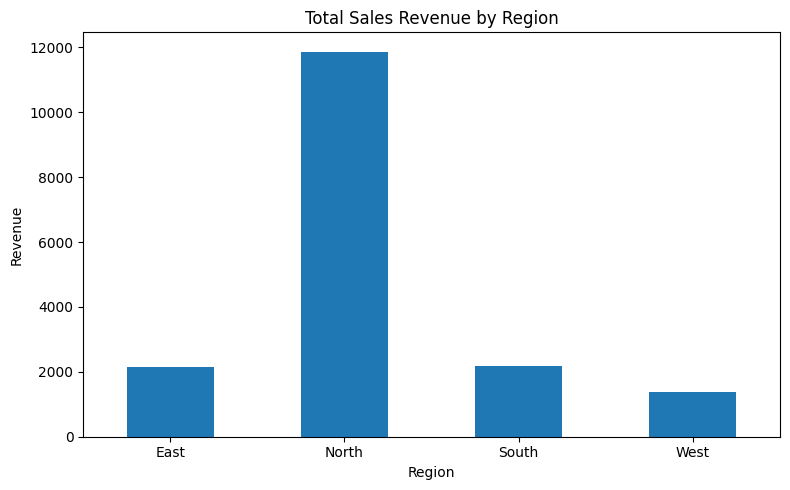

In [35]:
plt.figure(figsize=(8, 5))
region_revenue.plot(kind="bar")
plt.title("Total Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

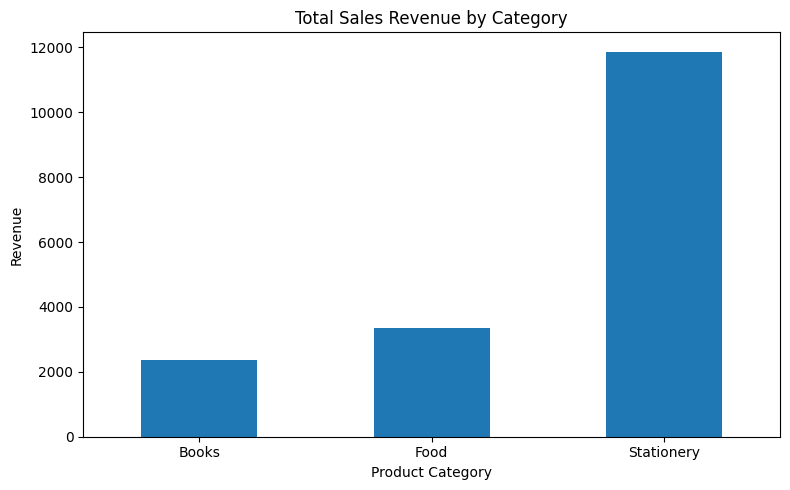

In [39]:
plt.figure(figsize=(8, 5))
category_revenue.plot(kind="bar")
plt.title("Total Sales Revenue by Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [40]:
highest_region = region_revenue.idxmax()
highest_region_revenue = region_revenue.max()
highest_category = category_revenue.idxmax()
highest_category_revenue = category_revenue.max()
print("Highest Revenue Region:", highest_region)
print("Revenue:", highest_region_revenue)
print("\nHighest Revenue Category:", highest_category)
print("Revenue:", highest_category_revenue)

Highest Revenue Region: North
Revenue: 11870.0

Highest Revenue Category: Stationery
Revenue: 11867.222222222223


In [41]:
df.to_csv("cleaned_sales.csv", index=False)
print("cleaned_sales.csv exported successfully!")

cleaned_sales.csv exported successfully!


# **Part B**

In [43]:
sales = pd.read_csv("cleaned_sales.csv")
print("Dataset loaded successfully!")
display(sales.head())
sales["tax_amount"] = sales["revenue"] * 0.05
display(sales.head())
sales.loc[
    sales["category"] == "Books",
    "unit_price"
] *= 1.10

Dataset loaded successfully!


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,10/1/2026,North,Food,2.0,120.0,240.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,Food,2.0,120.0,240.0,12.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0,12.5
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.5
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0,25.0


In [44]:
sales["revenue"] = sales["quantity"] * sales["unit_price"]
sales["tax_amount"] = sales["revenue"] * 0.05
display(sales.head())
print(sales["transaction_id"].tolist())
selected_id = sales["transaction_id"].iloc[0]

sales = sales[
    sales["transaction_id"] != selected_id
]

print("Removed transaction:", selected_id)
sales["review_status"] = "Pending"

display(sales.head())
sales = sales.drop(columns=["review_status"])
print(sales.columns.tolist())

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,Food,2.0,120.0,240.0,12.00
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00
4,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50


[1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020]
Removed transaction: 1001


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,review_status
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75,Pending
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50,Pending
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00,Pending
4,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50,Pending
5,1006,10/3/2026,West,Food,2.0,130.0,260.0,13.00,Pending


['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']


In [45]:
sales.to_csv("sales_updated.csv", index=False)
print("sales_updated.csv saved successfully!")

sales_updated.csv saved successfully!


In [46]:
updated_sales = pd.read_csv("sales_updated.csv")
print("First five rows:")
display(updated_sales.head())
print("\nFinal column names:")
print(updated_sales.columns.tolist())
print("\nFinal dataset shape:")
print(updated_sales.shape)

First five rows:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75
1,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50
2,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00
3,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50
4,1006,10/3/2026,West,Food,2.0,130.0,260.0,13.00



Final column names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']

Final dataset shape:
(19, 8)
